# Experiment 4: Logistic Regression

**Dataset:** Breast Cancer Wisconsin Diagnostic dataset (569 observations, 30 numerical features). It is built into scikit-learn; no manual Kaggle download is needed.

## Aim
Implement Logistic Regression to classify breast tumors as malignant or benign and evaluate the model.

## Note
This is a standard educational dataset for demonstrating binary classification. It is not a diagnostic tool.

Dataset shape: (569, 31)

First five rows:
   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  wo

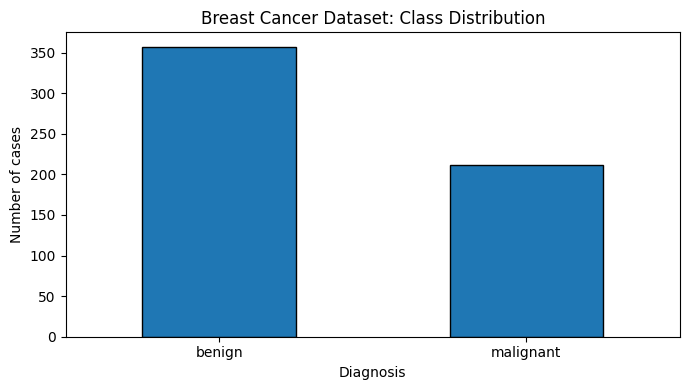

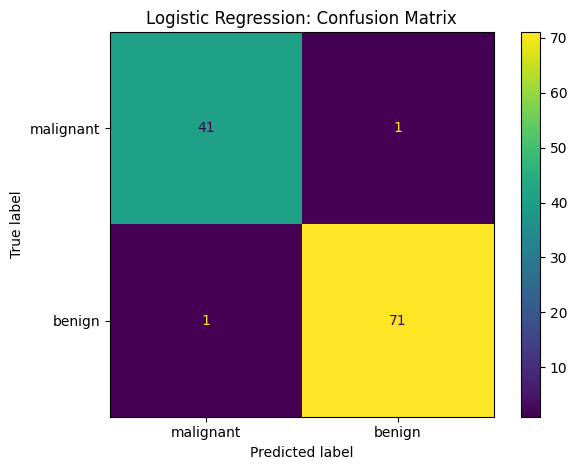

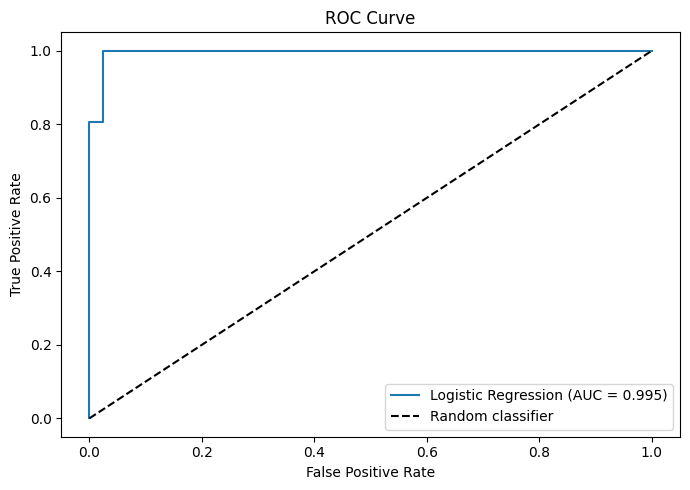


Example input (first test sample):
 mean radius  mean texture  mean perimeter  mean area  mean smoothness  mean compactness  mean concavity  mean concave points  mean symmetry  mean fractal dimension  radius error  texture error  perimeter error  area error  smoothness error  compactness error  concavity error  concave points error  symmetry error  fractal dimension error  worst radius  worst texture  worst perimeter  worst area  worst smoothness  worst compactness  worst concavity  worst concave points  worst symmetry  worst fractal dimension
       19.55         28.77           133.6     1207.0           0.0926            0.2063          0.1784               0.1144         0.1893                 0.06232        0.8426          1.199            7.158       106.4          0.006356            0.04765          0.03863               0.01519         0.01936                 0.005252         25.05          36.27            178.6      1926.0            0.1281             0.5329           0.42

In [1]:
# Experiment 4: Logistic Regression
# Dataset: Breast Cancer Wisconsin Diagnostic dataset (569 observations)
# Source: scikit-learn built-in dataset; no manual Kaggle download required.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, confusion_matrix, classification_report,
    ConfusionMatrixDisplay, roc_curve, roc_auc_score
)

# Step 1: Load dataset
dataset = load_breast_cancer(as_frame=True)
df = dataset.frame

print("Dataset shape:", df.shape)
print("\nFirst five rows:")
print(df.head())
print("\nClass distribution:")
print(df["target"].map({0: "malignant", 1: "benign"}).value_counts())
print("\nMissing values:", int(df.isnull().sum().sum()))

# Step 2: Separate features and target
X = df[dataset.feature_names]
y = df["target"]  # 0 = malignant, 1 = benign

# Step 3: Split data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("\nTraining observations:", len(X_train))
print("Testing observations:", len(X_test))

# Step 4: Create pipeline and train logistic regression
model = make_pipeline(
    StandardScaler(),
    LogisticRegression(max_iter=5000, random_state=42)
)
model.fit(X_train, y_train)

# Step 5: Make predictions
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

# Step 6: Evaluate model
print("\n--- Model Evaluation ---")
print("Accuracy:", round(accuracy_score(y_test, y_pred), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, y_prob), 4))
print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, target_names=dataset.target_names, zero_division=0
))

# Step 7: Visualize class distribution
class_counts = df["target"].map({0: "malignant", 1: "benign"}).value_counts()
plt.figure(figsize=(7, 4))
class_counts.plot(kind="bar", edgecolor="black")
plt.xlabel("Diagnosis")
plt.ylabel("Number of cases")
plt.title("Breast Cancer Dataset: Class Distribution")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# Step 8: Confusion matrix
cm = confusion_matrix(y_test, y_pred)
ConfusionMatrixDisplay(
    confusion_matrix=cm, display_labels=dataset.target_names
).plot(values_format="d")
plt.title("Logistic Regression: Confusion Matrix")
plt.tight_layout()
plt.show()

# Step 9: ROC curve
fpr, tpr, thresholds = roc_curve(y_test, y_prob)
plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, label=f"Logistic Regression (AUC = {roc_auc_score(y_test, y_prob):.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random classifier")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve")
plt.legend()
plt.tight_layout()
plt.show()

# Step 10: Predict one sample
sample = X_test.iloc[[0]]
prediction = model.predict(sample)[0]
probabilities = model.predict_proba(sample)[0]
predicted_label = dataset.target_names[prediction]

print("\nExample input (first test sample):")
print(sample.to_string(index=False))
print("Predicted diagnosis:", predicted_label)
print("Probability of malignant:", f"{probabilities[0]:.4f}")
print("Probability of benign:", f"{probabilities[1]:.4f}")
